# A first Caskade simulator

This CPU example checks native values and gradients, enables Niagara beneath the usual calls, then composes a functional derivative and batch. Run it with the Niagara project interpreter. The documentation build displays saved outputs without executing the notebook.

In [1]:
import sys

import caskade as ck
import torch

import niagara as ng

print(
    {
        "python": sys.version.split()[0],
        "niagara": ng.__version__,
        "caskade": ck.__version__,
        "torch": torch.__version__,
    }
)
print("Niagara import:", ng.__file__)
print("Caskade import:", ck.__file__)

{'python': '3.11.1', 'niagara': '0.7.0', 'caskade': '1.1.5', 'torch': '2.12.0+cu126'}
Niagara import: G:\Qsync\Maitrise\Projects\Niagara\src\niagara\__init__.py
Caskade import: G:\Qsync\Maitrise\Projects\Niagara\.venv\Lib\site-packages\caskade\__init__.py


In [2]:
class Signal(ck.Module):
    def __init__(self):
        super().__init__("signal")
        self.amplitude = ck.Param("amplitude", None)
        self.phase = ck.Param("phase", None)
        self.grid = torch.linspace(-1, 1, 16, dtype=torch.float64)

    @ck.forward
    def __call__(self, amplitude, phase):
        return amplitude * torch.sin(self.grid + phase)


sim = Signal()
values = {"amplitude": 1.2, "phase": 0.3}
params = torch.tensor([values[p.name] for p in sim.dynamic_params], dtype=torch.float64)
reference = sim(params).detach()
native_class = type(sim)
print("Packed order:", [p.name for p in sim.dynamic_params])

Packed order: ['amplitude', 'phase']


In [3]:
with ng.enable(sim, default="cpu", example=params) as engine:
    image = sim(params)
    torch.testing.assert_close(image, reference)
    q = params.detach().requires_grad_()
    gradient = torch.autograd.grad(sim(q).square().sum(), q)[0]
    with engine.session():
        torch.testing.assert_close(sim(params), reference)
    print("Prepared backends:", [program.backend for program in engine.programs])

assert type(sim) is native_class
q = params.detach().requires_grad_()
native_gradient = torch.autograd.grad(sim(q).square().sum(), q)[0]
torch.testing.assert_close(gradient, native_gradient)
print("All ordinary gradients agree:", gradient)

Prepared backends: ['torchscript', 'torchscript']
All ordinary gradients agree: tensor([12.8979,  5.1738], dtype=torch.float64)


In [4]:
render = ng.compile_model(sim, params, backend="eager")
loss = render.transform(lambda f: lambda p: f(p).square().sum(), params)
derivative = loss.transform(torch.func.grad_and_value, params)
functional_gradient, value = derivative(params)
torch.testing.assert_close(functional_gradient, native_gradient)

batch = params.repeat(3, 1)
batched = ng.vmap(derivative, batch)
gradients, values = batched(batch)
torch.testing.assert_close(gradients, native_gradient.expand_as(gradients))
print("Batched gradients:", gradients.shape, "values:", values.shape)

Batched gradients:

 torch.Size([3, 2]) values: torch.Size([3])


The comparisons check every parameter of this small CPU model. Two-GPU performance and scientific inference convergence require separate validation.

## Simulator output

The captured program reproduces the native signal on the same sample grid.

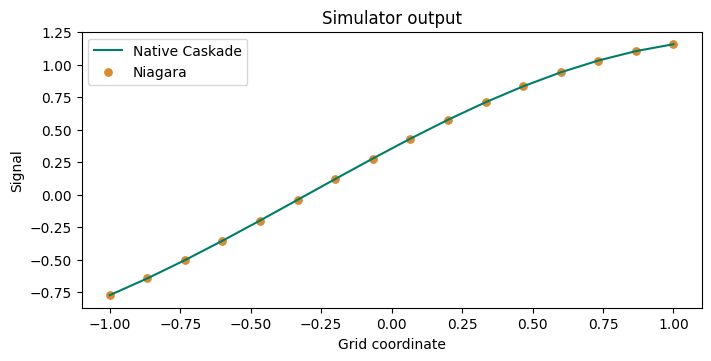

In [5]:
%matplotlib inline
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 3.5), constrained_layout=True)
ax.plot(sim.grid.numpy(), reference.numpy(), label="Native Caskade", color="#007d68")
ax.scatter(sim.grid.numpy(), image.detach().numpy(), label="Niagara", color="#d78b33", s=28)
ax.set(xlabel="Grid coordinate", ylabel="Signal", title="Simulator output")
ax.legend()
plt.show()